# Exploratory Data Analysis

## Objectives

- Understand AI adoption patterns.
- Explore workforce displacement.
- Examine job creation trends.
- Investigate reskilling investment.
- Compare countries.
- Compare industries.
- Compare skill categories.

In [2]:
import pandas as pd
import numpy as np
import os

In [3]:
data_path = "../../2. Data/Cleaned"

country = pd.read_csv(os.path.join(data_path, "dim_country_clean.csv"))
date = pd.read_csv(os.path.join(data_path, "dim_date_clean.csv"))
industry = pd.read_csv(os.path.join(data_path, "dim_industry_clean.csv"))
skill = pd.read_csv(os.path.join(data_path, "dim_skill_category_clean.csv"))
fact = pd.read_csv(os.path.join(data_path, "fact_workforce_ai_index_clean.csv"))

In [4]:
eda_df = (
    fact
    .merge(country, on="country_id", how="left")
    .merge(industry, on="industry_id", how="left")
    .merge(skill, on="skill_category_id", how="left")
    .merge(date, on="date_id", how="left")
)

In [5]:
eda_df.shape


(300, 44)

In [6]:
kpis = {
    "Total Records": len(eda_df),
    "Countries": eda_df["country_name"].nunique(),
    "Industries": eda_df["industry_name"].nunique(),
    "Skill Categories": eda_df["skill_category_name"].nunique(),
    "Average AI Adoption (%)": round(eda_df["ai_adoption_rate"].mean(), 2),
    "Average Productivity Score": round(eda_df["productivity_impact_score"].mean(), 2),
    "Average Displacement Risk": round(eda_df["displacement_risk_index"].mean(), 2),
    "Total Jobs Created": eda_df["jobs_created_count"].sum(),
    "Total Jobs Displaced": eda_df["jobs_displaced_count"].sum(),
    "Total Reskilling Investment ($)": round(eda_df["reskilling_investment_usd"].sum(), 2)
}

pd.DataFrame(kpis.items(), columns=["Metric", "Value"])

,Metric,Value
0,Total Records,300.00
1,Countries,30.00
2,Industries,25.00
3,Skill Categories,8.00
4,Average AI Adoption (%),30.65
5,Average Productivity Score,5.36
6,Average Displacement Risk,4.26
7,Total Jobs Created,296355.00
8,Total Jobs Displaced,586785.00
9,Total Reskilling Investment ($),61651485.20


In [7]:
eda_df["net_jobs"] = (
    eda_df["jobs_created_count"]
    - eda_df["jobs_displaced_count"]
)

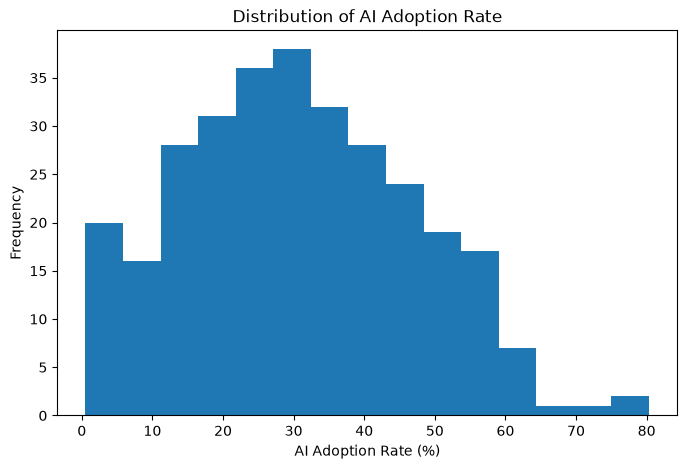

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(eda_df["ai_adoption_rate"], bins=15)

plt.title("Distribution of AI Adoption Rate")
plt.xlabel("AI Adoption Rate (%)")
plt.ylabel("Frequency")

plt.show()

In [9]:
eda_df["ai_adoption_rate"].describe()

count    300.000000
mean      30.646467
std       16.508854
min        0.500000
25%       18.540000
50%       29.680000
75%       41.672500
max       80.330000
Name: ai_adoption_rate, dtype: float64

AI adoption is concentrated around 20–40%, with an average adoption rate of 30.65%. Only a small number of country-industry-skill combinations exhibit adoption rates above 60%, indicating that widespread AI adoption remains limited to a few highly advanced segments

In [10]:
gen_ai_adoption = (
    eda_df.groupby("generative_ai_era")["ai_adoption_rate"]
    .mean()
    .reset_index()
)

In [11]:
gen_ai_adoption["generative_ai_era"] = gen_ai_adoption["generative_ai_era"].map({
    False: "Before GenAI",
    True: "After GenAI"
})

gen_ai_adoption 

,generative_ai_era,ai_adoption_rate
0,Before GenAI,20.367710
1,After GenAI,38.614024


Average AI adoption increased from 20.37% before the Generative AI era to 38.61% after its introduction, representing an increase of approximately 90%. This indicates that Generative AI significantly accelerated AI adoption across countries, industries, and skill categories.

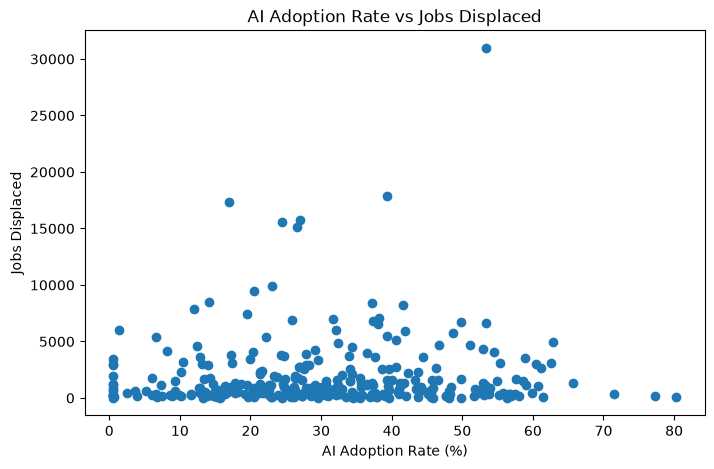

In [12]:
plt.figure(figsize=(8,5))

plt.scatter(
    eda_df["ai_adoption_rate"],
    eda_df["jobs_displaced_count"]
)

plt.title("AI Adoption Rate vs Jobs Displaced")
plt.xlabel("AI Adoption Rate (%)")
plt.ylabel("Jobs Displaced")

plt.show()

In [13]:
eda_df[["ai_adoption_rate", "jobs_displaced_count"]].corr()

,ai_adoption_rate,jobs_displaced_count
ai_adoption_rate,1.000000,0.037848
jobs_displaced_count,0.037848,1.000000


Most data points are concentrated between 10%–50% AI adoption and below 5,000 jobs displaced.
A few outliers show very high job displacement, but they are rare.
Even segments with high AI adoption (70–80%) sometimes have very low job displacement.

The analysis shows almost no correlation (r = 0.038) between AI adoption rate and jobs displaced. This suggests that higher AI adoption alone does not necessarily result in greater workforce displacement. Other factors, such as industry characteristics, skill category, automation susceptibility, and organizational AI strategy, are likely to play a more significant role in determining job displacement

## Which industries have the highest average job displacement?

In [14]:
industry_displacement = (
    eda_df.groupby("industry_name")["jobs_displaced_count"]
    .mean()
    .sort_values(ascending=False)
)

industry_displacement

industry_name
Media & Entertainment         4093.200000
Food & Beverage               3484.111111
Manufacturing                 3279.777778
Professional Services         2640.272727
Healthcare                    2366.000000
Automotive                    2269.555556
Hospitality & Tourism         2267.642857
Education                     2194.928571
Retail & E-commerce           2151.739130
Information Technology        2142.200000
Agriculture                   1972.000000
Financial Services            1801.250000
Aerospace & Defence           1740.769231
Public Health                 1735.000000
Real Estate                   1670.750000
Transportation & Logistics    1666.100000
Construction                  1600.375000
Government & Public Sector    1549.363636
Insurance                     1438.500000
Pharmaceuticals               1377.800000
Legal Services                1268.000000
Mining & Resources            1183.000000
Energy & Utilities             960.538462
Telecommunications  

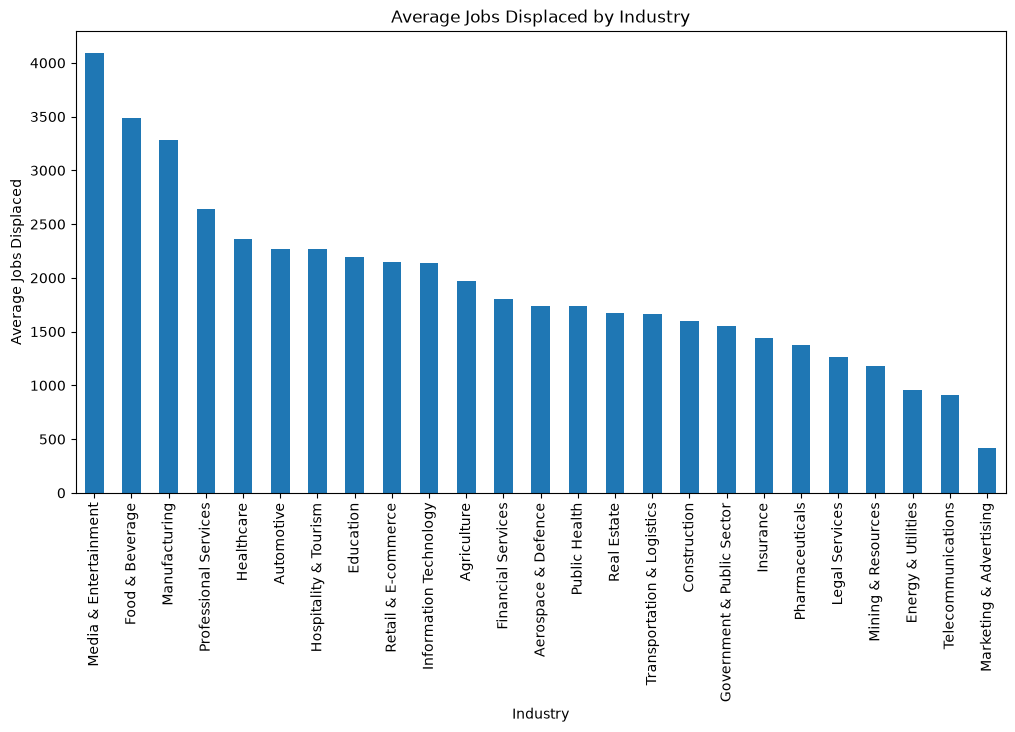

In [15]:
plt.figure(figsize=(12,6))

industry_displacement.plot(kind="bar")

plt.title("Average Jobs Displaced by Industry")
plt.xlabel("Industry")
plt.ylabel("Average Jobs Displaced")
plt.xticks(rotation=90)

plt.show()

In [16]:
skill_risk = (
    eda_df.groupby("skill_category_name")["displacement_risk_index"]
    .mean()
    .sort_values(ascending=False)
)

skill_risk

skill_category_name
Manual & Physical            4.564872
Technical & Digital          4.381579
Social & Interpersonal       4.326279
Manual Skilled Trades        4.261429
Administrative & Clerical    4.242432
Cognitive & Analytical       4.204242
Creative & Design            4.167879
Managerial & Strategic       3.963810
Name: displacement_risk_index, dtype: float64

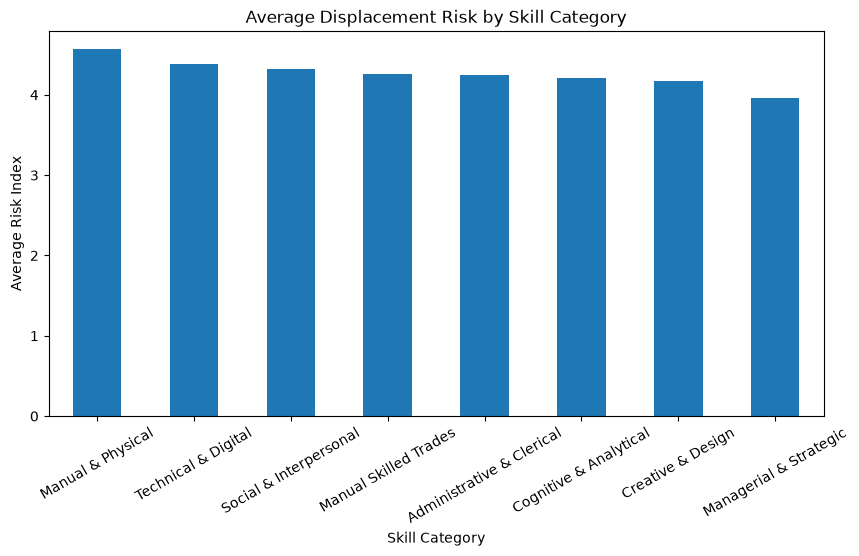

In [17]:
plt.figure(figsize=(10,5))

skill_risk.plot(kind="bar")

plt.title("Average Displacement Risk by Skill Category")
plt.xlabel("Skill Category")
plt.ylabel("Average Risk Index")

plt.xticks(rotation=30)

plt.show()

Manual & Physical skills exhibit the highest average displacement risk (4.56), indicating that workers performing routine or repetitive tasks are more vulnerable to AI-driven automation. In contrast, Managerial & Strategic roles have the lowest average displacement risk (3.96), suggesting that leadership and decision-oriented roles remain relatively resilient to automation. Overall, the relatively small variation in risk scores indicates that AI is expected to influence all skill categories to some extent, although the level of impact differs.

## Is reskilling investment keeping pace with displacement risk?

In [18]:
skill_investment = (
    eda_df.groupby("skill_category_name")["reskilling_investment_usd"]
    .mean()
)

skill_investment

skill_category_name
Administrative & Clerical    201047.854054
Cognitive & Analytical       175328.309091
Creative & Design            298242.508182
Managerial & Strategic       202936.222381
Manual & Physical            145154.799744
Manual Skilled Trades         90552.144000
Social & Interpersonal       292965.312558
Technical & Digital          227202.253158
Name: reskilling_investment_usd, dtype: float64

In [19]:
comparison = pd.DataFrame({
    "Average Risk": skill_risk,
    "Average Investment": skill_investment
})

comparison

,Average Risk,Average Investment
skill_category_name,,
Administrative & Clerical,4.242432,201047.854054
Cognitive & Analytical,4.204242,175328.309091
Creative & Design,4.167879,298242.508182
Managerial & Strategic,3.963810,202936.222381
Manual & Physical,4.564872,145154.799744
Manual Skilled Trades,4.261429,90552.144000
Social & Interpersonal,4.326279,292965.312558
Technical & Digital,4.381579,227202.253158


In [20]:
comparison.sort_values(
    by="Average Risk",
    ascending=False
)

,Average Risk,Average Investment
skill_category_name,,
Manual & Physical,4.564872,145154.799744
Technical & Digital,4.381579,227202.253158
Social & Interpersonal,4.326279,292965.312558
Manual Skilled Trades,4.261429,90552.144000
Administrative & Clerical,4.242432,201047.854054
Cognitive & Analytical,4.204242,175328.309091
Creative & Design,4.167879,298242.508182
Managerial & Strategic,3.963810,202936.222381


The analysis indicates that reskilling investment is not perfectly aligned with displacement risk. While Technical & Digital and Social & Interpersonal skills receive substantial investment relative to their risk levels, Manual Skilled Trades exhibit relatively high displacement risk but receive the lowest average reskilling investment. This suggests a potential funding gap where additional reskilling initiatives may be required. Conversely, Creative & Design receives one of the highest investment levels despite having comparatively lower displacement risk.

# Do Developed and Emerging economies adopt AI at different rates?


In [21]:
development_ai = (
    eda_df.groupby("development_tier")["ai_adoption_rate"]
    .mean()
    .sort_values(ascending=False)
)

development_ai

development_tier
Developed    30.981488
Emerging     30.220076
Name: ai_adoption_rate, dtype: float64

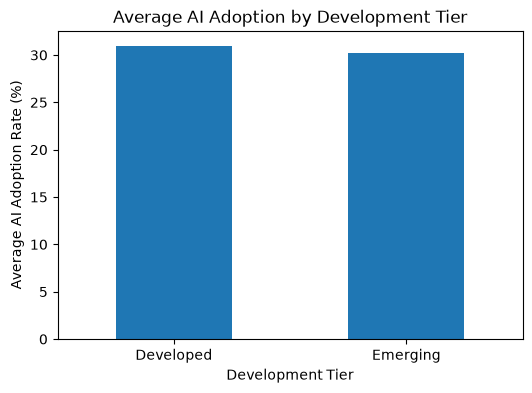

In [22]:
plt.figure(figsize=(6,4))

development_ai.plot(kind="bar")

plt.title("Average AI Adoption by Development Tier")
plt.xlabel("Development Tier")
plt.ylabel("Average AI Adoption Rate (%)")

plt.xticks(rotation=0)

plt.show()

Developed economies showed a marginally higher AI adoption rate (30.98%) compared to emerging economies (30.22%). However, the difference was minimal, suggesting that AI adoption is occurring at a comparable pace across both development tiers in this dataset.

# Is AI creating enough jobs to offset the jobs it is displacing?

In [23]:
job_summary = {
    "Jobs Created": eda_df["jobs_created_count"].sum(),
    "Jobs Displaced": eda_df["jobs_displaced_count"].sum()
}

job_summary

{'Jobs Created': np.int64(296355), 'Jobs Displaced': np.int64(586785)}

AI-driven displacement currently exceeds job creation in this dataset. Approximately 586,785 jobs were displaced compared to 296,355 jobs created, indicating that AI is eliminating jobs at nearly twice the rate it is generating new employment. This highlights the growing importance of reskilling initiatives and workforce transition policies.

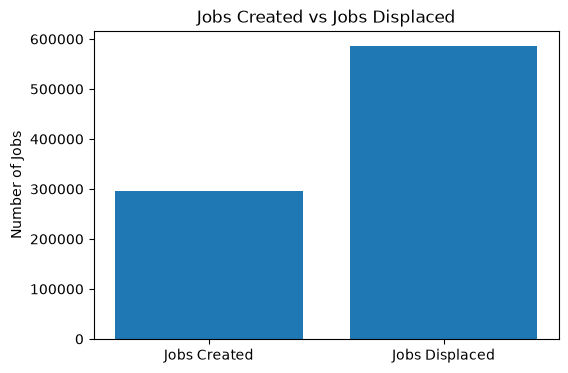

In [25]:
plt.figure(figsize=(6,4))

plt.bar(job_summary.keys(), job_summary.values())

plt.title("Jobs Created vs Jobs Displaced")
plt.ylabel("Number of Jobs")

plt.show()

# What relationships exist between the important numerical variables?

In [26]:
corr = eda_df[
    [
        "ai_adoption_rate",
        "productivity_impact_score",
        "displacement_risk_index",
        "jobs_displaced_count",
        "jobs_created_count",
        "reskilling_investment_usd",
        "avg_wage_change_pct",
        "ai_tool_usage_hours_per_week"
    ]
].corr()

corr

,ai_adoption_rate,productivity_impact_score,displacement_risk_index,jobs_displaced_count,jobs_created_count,reskilling_investment_usd,avg_wage_change_pct,ai_tool_usage_hours_per_week
ai_adoption_rate,1.000000,-0.033148,0.063495,0.037848,0.027825,0.134407,0.055099,0.271241
productivity_impact_score,-0.033148,1.000000,0.033400,-0.005451,-0.028615,0.042464,-0.028722,-0.041193
displacement_risk_index,0.063495,0.033400,1.000000,0.258273,0.260087,0.166340,0.056391,-0.034077
jobs_displaced_count,0.037848,-0.005451,0.258273,1.000000,0.898328,0.016437,-0.054686,-0.071012
jobs_created_count,0.027825,-0.028615,0.260087,0.898328,1.000000,0.026100,-0.046286,-0.047293
reskilling_investment_usd,0.134407,0.042464,0.166340,0.016437,0.026100,1.000000,-0.054397,-0.055749
avg_wage_change_pct,0.055099,-0.028722,0.056391,-0.054686,-0.046286,-0.054397,1.000000,0.085792
ai_tool_usage_hours_per_week,0.271241,-0.041193,-0.034077,-0.071012,-0.047293,-0.055749,0.085792,1.000000


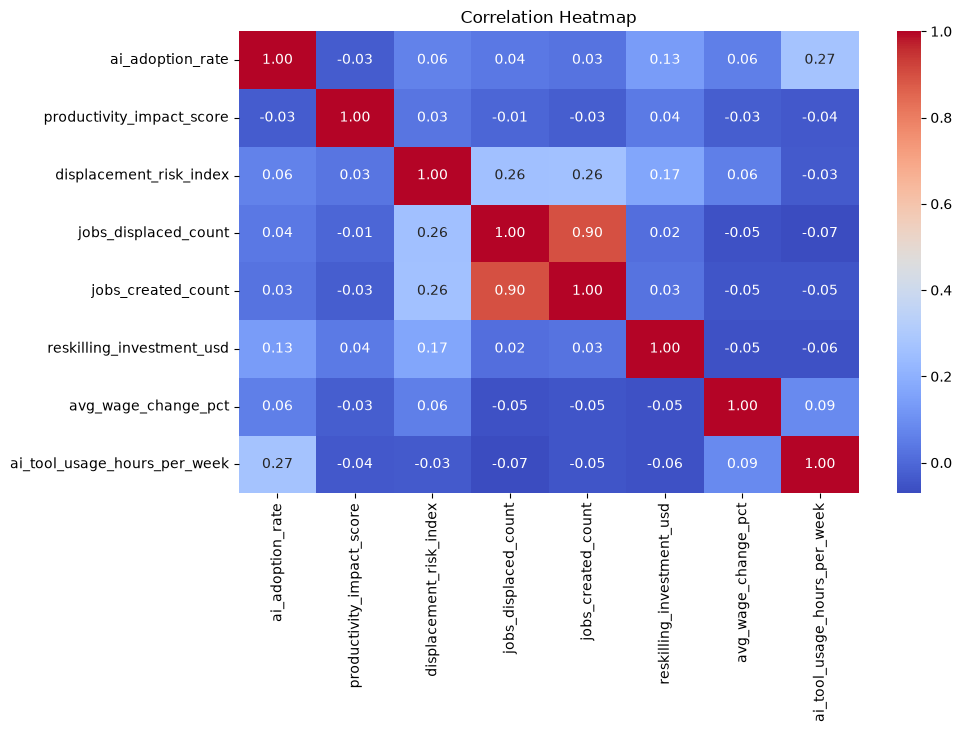

In [27]:
import seaborn as sns

plt.figure(figsize=(10,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

# 📊 Exploratory Data Analysis (EDA) Summary

## Objective

The objective of this exploratory data analysis was to understand how Artificial Intelligence (AI) adoption has impacted industries, countries, and skill categories between 2021 and 2024. The analysis focused on workforce displacement, job creation, reskilling investment, and AI adoption trends to generate insights for policymakers.

---

# 1. Dataset Quality

### Findings

- All dimension tables contained no missing values.
- The fact table contained only 3% missing values in:
  - avg_wage_change_pct
  - ai_tool_usage_hours_per_week
- Missing values were imputed using the median.
- No duplicate records were found.

### Conclusion

The dataset was clean and suitable for further analysis.

---

# 2. Overall AI Adoption

### Findings

- Average AI Adoption Rate = **30.65%**
- Most records lie between **20% and 40%**
- Very few observations exceed **60%**

### Business Insight

AI adoption is currently moderate across most country-industry-skill combinations, with only a few highly advanced segments showing widespread adoption.

---

# 3. AI Adoption Before vs After the Generative AI Era

### Findings

Before Generative AI:

- 20.37%

After Generative AI:

- 38.61%

Increase:

- Approximately 90%

### Business Insight

The emergence of Generative AI significantly accelerated AI adoption across countries and industries.

---

# 4. AI Adoption vs Job Displacement

### Findings

Correlation:

- 0.04

### Business Insight

Almost no linear relationship exists between AI adoption rate and jobs displaced.

This suggests that AI adoption alone does not determine workforce displacement. Other factors such as industry characteristics, automation susceptibility, workforce skills, and national policies play a much larger role.

---

# 5. Industry-Level Job Displacement

### Highest Average Job Displacement

- Media & Entertainment
- Food & Beverage
- Manufacturing

### Lowest Average Job Displacement

- Marketing & Advertising

### Business Insight

Industries involving repetitive and highly automatable tasks experience greater workforce disruption than knowledge-intensive or creative industries.

---

# 6. Skill Categories with Highest Displacement Risk

### Highest Risk

- Manual & Physical
- Technical & Digital
- Social & Interpersonal

### Lowest Risk

- Managerial & Strategic

### Business Insight

Workers performing routine physical or technical tasks face higher AI-driven displacement risk, whereas strategic and managerial roles remain comparatively resilient.

---

# 7. Reskilling Investment vs Displacement Risk

### Findings

Higher-risk skill categories do not consistently receive the highest reskilling investment.

Example:

- Manual & Physical skills have the highest displacement risk but receive lower average investment than some lower-risk categories.

### Business Insight

Current reskilling investments are not perfectly aligned with workforce risk. Governments and organizations should prioritize funding toward the most vulnerable skill groups.

---

# 8. AI Adoption by Development Tier

### Findings

Developed Countries

- 30.98%

Emerging Countries

- 30.22%

Difference

- 0.76%

### Business Insight

Developed countries exhibit only slightly higher AI adoption than emerging economies, suggesting that AI adoption is becoming widespread globally rather than remaining concentrated in advanced economies.

---

# 9. Jobs Created vs Jobs Displaced

### Findings

Jobs Created

- 296,355

Jobs Displaced

- 586,785

Overall Ratio

- Approximately 2 : 1

### Business Insight

Across the dataset, AI displaced nearly twice as many jobs as it created, highlighting the importance of workforce reskilling and transition policies.

This ratio represents total jobs across the dataset and should not be interpreted as AI directly causing two job losses for every individual AI implementation.

---

# 10. Correlation Analysis

### Strongest Positive Correlation

Jobs Created ↔ Jobs Displaced

Correlation:

- 0.90

### Business Insight

Industries experiencing higher workforce disruption also tend to create more AI-related employment opportunities.

This indicates workforce transformation rather than simple job elimination.

---

# Key Findings

- AI adoption accelerated significantly after the arrival of Generative AI.
- AI adoption alone does not explain workforce displacement.
- Media & Entertainment experienced the highest average job displacement.
- Manual & Physical skills showed the greatest displacement risk.
- Reskilling investment is not fully aligned with workforce risk.
- AI adoption rates are similar across developed and emerging economies.
- Overall job displacement currently exceeds job creation.
- AI transformation creates both new opportunities and workforce disruption simultaneously.

---

# Final Conclusion

The analysis indicates that AI is reshaping the labor market through workforce transformation rather than simple job replacement. While Generative AI has accelerated adoption globally, workforce impacts vary considerably across industries and skill categories. The findings suggest that targeted reskilling investments, rather than broad AI adoption policies alone, will be essential for reducing displacement risk and preparing workers for future AI-driven economies.